# Cap. 5 · AR(1), vida media y densidad espectral
*Proyecto DAT 262 · Monitor de estrés cambiario y monetario de Bolivia*

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from stress_monitor import data, stationarity as stat, markov as mk, forecasting as fc, gap as gp, simulation as sim, demo
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})
m = data.load_monthly(); d = data.load_daily_key()
print("Datos mensuales:", m.index.min().date(), "→", m.index.max().date(), f"({len(m)} meses)")

Datos mensuales: 1989-01-31 → 2026-10-31 (454 meses)


**AR(1):** $G_t=c+\phi G_{t-1}+\varepsilon_t$. Media de largo plazo $c/(1-\phi)$ y **vida media** $\ln(0{,}5)/\ln\phi$ (tiempo para que se cierre la mitad de una desviación). Densidad espectral: $f(\omega)$ estimada con el periodograma.

Picos: [2.8, 11.9, 2.8] meses


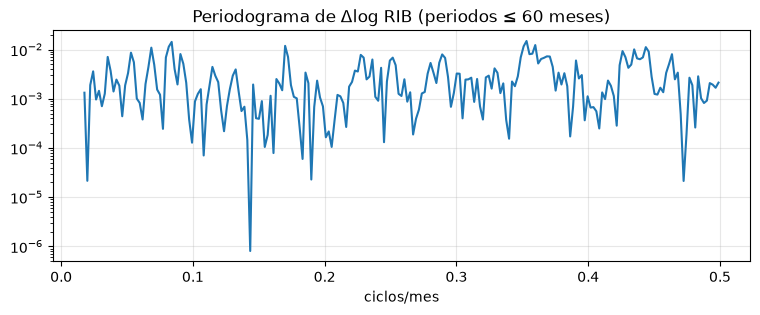

In [2]:
dl = np.log(m['rib']).diff().dropna()
sp = stat.periodogram(dl, min_freq=1/60)
fig, ax = plt.subplots(figsize=(9, 3)); ax.semilogy(sp['f'], sp['pxx']); ax.set_xlabel('ciclos/mes'); ax.set_title('Periodograma de Δlog RIB (periodos ≤ 60 meses)')
print('Picos:', [round(p['periodo_meses'], 1) for p in sp['picos']], 'meses')

### Brecha oficial–paralelo con datos observados
Paralelo: mediana P2P de [paralelo.bo](https://paralelo.bo/api/v1/historical.csv), CC BY 4.0. Oficial diario: [BCB TCO](https://www.bcb.gob.bo/grafico_evolutivo/download.php?serie=tipo_de_cambio&format=csv) desde 29-jun-2026. La mediana P2P es un anuncio y no se mezcla con Binance ni el PDF.

In [3]:
col, pdf = data.load_p2p(); ext = data.load_external_parallel(); tco = data.load_bcb_tco(); g = data.build_gap(m, d, col, pdf, external=ext, official_tco=tco)
assert len(ext) >= 30, 'Descargue el historial real: python -m bcb_pipeline fetch-history'
r = gp.ar1_gap(g['brecha_pct'][g.index >= data.FECHA_FLEXIBLE])
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in r.items() if k in ('n', 'phi', 'vida_media', 'media_larga', 'adf')})

{'n': 138, 'phi': 0.842, 'vida_media': 4.018, 'media_larga': 0.635, 'adf': {'estadistico': -4.68819720270228, 'p_valor': 8.855557920963721e-05, 'rezagos': 5, 'n': 132, 'critico_5%': np.float64(-2.8836966192225284), 'estacionaria_5%': True}}


Text(0.5, 1.0, 'Brecha observada (%)')

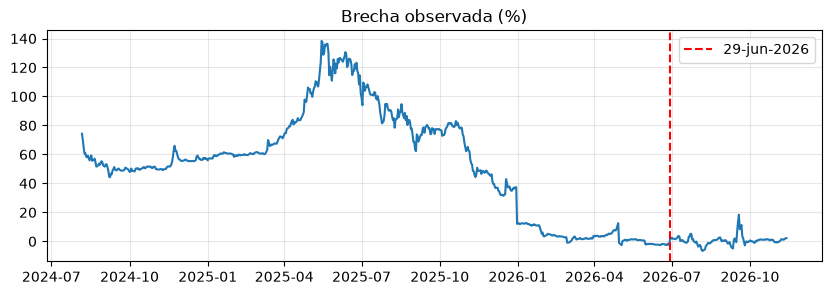

In [4]:
x = g['brecha_pct']
fig, ax = plt.subplots(figsize=(10, 3)); ax.plot(x); ax.axvline(data.FECHA_FLEXIBLE, c='r', ls='--', label='29-jun-2026'); ax.legend(); ax.set_title('Brecha observada (%)')

### H3 y H5 con datos reales
H3 compara volatilidad de la misma mediana P2P entre 4-may y 3-sep-2026; H5 usa retornos hábiles desde julio. Los valores de Granger son predictivos, no causales.

In [5]:
ret = gp.daily_returns(g['paralelo']); ret = ret[(ret.index >= '2026-05-04') & (ret.index <= '2026-09-03')]
print('H3:', gp.volatility_by_regime(ret, str(data.FECHA_FLEXIBLE.date())))
ll = gp.lead_lag(g['paralelo'], g['oficial']); ll.pop('cc', None); print('H5:', ll)

H3: {'ok': True, 'n_antes': 56, 'n_despues': 67, 'sd_antes': 0.004696869299922601, 'sd_despues': 0.011234882921635206, 'razon': 2.3919939440981133, 'levene_p': 3.8246501760156e-05}
H5: {'ok': True, 'n': 97, 'cambios_tco': 85, 'rezago_max': 1, 'corr_max': 0.6576996723573723, 'granger_par→of': {1: 9.211884475647662e-10, 2: 5.456743741498792e-07, 3: 3.4753257904042377e-06, 4: 1.552214222989401e-05, 5: 5.7445944043892935e-08}, 'granger_of→par': {1: 0.29282244982319167, 2: 0.04702837625087386, 3: 0.11084762052022433, 4: 0.48871352045182737, 5: 0.36547789124276997}}
